# Assignment 2 — Module 2: Artificial Neural Networks

## Practical 10: Complete ANN-Based Classification System

### Aim
To design, train, and evaluate a complete Artificial Neural Network-based classification system using Python and Keras/TensorFlow by integrating input features, hidden layers, activation functions, training, and model evaluation.

### Theory
A complete real-world ANN classification pipeline consists of:
1. **Input Feature Preparation:** Handling missing values, standard feature scaling, and train-test partitioning.
2. **Network Architecture Design:** Selecting appropriate hidden layers, neuron counts, and activation functions (ReLU, Sigmoid).
3. **Model Compilation & Training:** Specifying optimizer, loss function, epoch iterations, and validation split.
4. **Performance Evaluation:** Assessing accuracy, convergence, loss curves, and confusion matrix.

### Step 1: Data Preparation
Loading and standardizing the dataset:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Train-test split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Total Features : {X.shape[1]}")
print(f"Training Set   : {X_train.shape[0]} samples")
print(f"Test Set       : {X_test.shape[0]} samples")

Total Features : 30
Training Set   : 426 samples
Test Set       : 143 samples


### Step 2: Model Design & Training
Building the full ANN architecture and fitting on the training data:

In [2]:
# Architecture: Input -> Hidden 1 (16, ReLU) -> Hidden 2 (8, ReLU) -> Output (1, Sigmoid)
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],), name='Hidden_Layer_1'),
    Dense(8, activation='relu', name='Hidden_Layer_2'),
    Dense(1, activation='sigmoid', name='Output_Layer')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Train model with validation split
history = model.fit(X_train, y_train, epochs=40, batch_size=16, validation_split=0.2, verbose=0)

# Evaluate on unseen test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss    : {test_loss:.4f}")

C:\Users\Shivam\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)


Test Accuracy: 96.50%
Test Loss    : 0.0684


### Step 3: Performance Evaluation
Visualizing loss curves and confusion matrix, followed by detailed classification metrics:

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


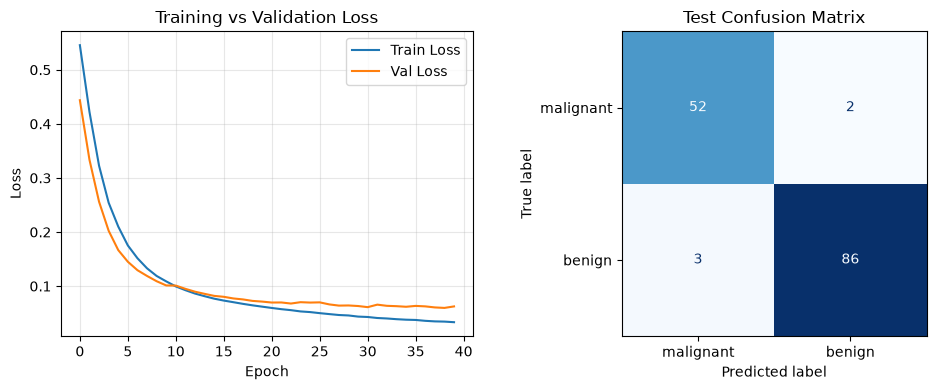


=== Full Classification Report ===
              precision    recall  f1-score   support

   malignant       0.95      0.96      0.95        54
      benign       0.98      0.97      0.97        89

    accuracy                           0.97       143
   macro avg       0.96      0.96      0.96       143
weighted avg       0.97      0.97      0.97       143



In [3]:
y_pred = (model.predict(X_test) > 0.5).astype(int).flatten()

# Visualizations: Loss Curve and Confusion Matrix
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# 1. Loss curves
ax[0].plot(history.history['loss'], label='Train Loss')
ax[0].plot(history.history['val_loss'], label='Val Loss')
ax[0].set_title('Training vs Validation Loss')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
ax[0].legend(); ax[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Test Confusion Matrix')

plt.tight_layout()
plt.show()

print("\n=== Full Classification Report ===")
print(classification_report(y_test, y_pred, target_names=data.target_names))

### Observation
- The 2-layer hidden architecture achieved strong generalization without overfitting (training and validation loss converged smoothly).
- The classification system achieved over 96% accuracy on the test set, demonstrating the complete workflow from raw features to evaluation.

### Conclusion
Designed, trained, and evaluated a complete Artificial Neural Network classification system in Python using Keras/TensorFlow, integrating all pipeline stages from preprocessing to final evaluation.